### OA Classification Pipeline
#### Reesink Lab
##### Classification model of Lectin Microarray Data from Human, Dog, and Horse
README.md for full details

### STEP 1: Load packages and set seed

In [1]:
# Step 1: Load packages and set seed
# Import packages
import pandas as pd
import numpy as np
import re
from pycaret.classification import *
import shap
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from sklearn.model_selection import StratifiedGroupKFold
import shap
from pycaret.classification import get_config
from sklearn.metrics import (confusion_matrix, ConfusionMatrixDisplay,
                             roc_curve, auc, precision_recall_curve,
                             average_precision_score, classification_report,
                             roc_auc_score, recall_score, precision_score)
from sklearn.model_selection import cross_val_predict
from sklearn.base import clone
SEED = 42
sgkf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)


### STEP 2: Upload dataset

In [2]:
# Step 2a: Upload full dataset
# Upload df
df = pd.read_csv("OAcombined.csv")

# Strip whitespace from column names — several lectin names have trailing spaces
df.columns = df.columns.str.strip()

print(df.shape)
print(df['Condition'].value_counts())
print(df['Species'].value_counts())
print(pd.crosstab(df['Species'], df['Condition']))
print(df.isnull().sum().sum())

(223, 71)
Condition
OA         163
Healthy     60
Name: count, dtype: int64
Species
Horse    118
Dog       59
Human     46
Name: count, dtype: int64
Condition  Healthy  OA
Species               
Dog              9  50
Horse           41  77
Human           10  36
0


In [3]:
# Step 2b: Derive paired human nums from data
human = df[df['Species'] == 'Human'].copy()
human['num'] = human['samples'].str.extract(r'(\d+)')
paired_human_nums = set(
    human.groupby('num')['Condition'].nunique().loc[lambda s: s > 1].index
)
print(f"Paired human nums: {paired_human_nums}")  # verify matches your hardcoded set

def build_subject_id(row):
    idx = row['samples'].strip()
    species = row['Species']
    if species == 'Human':
        num = re.search(r'\d+', idx).group()
        return f"Human_paired_{num}" if num in paired_human_nums else f"Human_OA_{num}"
    return f"{species}_{idx}"

df['subject_id'] = df.apply(build_subject_id, axis=1)

Paired human nums: {'12', '11', '9', '21', '10', '17', '18', '23', '8', '19'}


### STEP 3: Data splitting and external holdout

In [4]:
# Step 3a: Data splitting — outer holdout (unchanged, this is correct)
sgkf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
train_idx, holdout_idx = next(sgkf.split(df, df['Condition'], groups=df['subject_id']))

train_data = df.iloc[train_idx].reset_index(drop=True)
holdout_data = df.iloc[holdout_idx].reset_index(drop=True)

assert set(train_data['subject_id']) & set(holdout_data['subject_id']) == set(), \
    "Subject leakage detected between train and holdout!"

print("Train shape:", train_data.shape)
print("Holdout shape:", holdout_data.shape)
print("\nTrain Condition:\n", train_data['Condition'].value_counts())
print("\nHoldout Condition:\n", holdout_data['Condition'].value_counts())
print("\nTrain Species:\n", train_data['Species'].value_counts())
print("\nHoldout Species:\n", holdout_data['Species'].value_counts())

train_data.to_csv("train_data.csv", index=False)
holdout_data.to_csv("holdout_data.csv", index=False)
print("\nSaved train_data.csv and holdout_data.csv")


# Step 3b: Group-aware inner split
inner_sgkf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED + 1)
inner_train_idx, inner_test_idx = next(inner_sgkf.split(
    train_data, train_data['Condition'], groups=train_data['subject_id']
))

oa_train = train_data.iloc[inner_train_idx].reset_index(drop=True)
oa_test = train_data.iloc[inner_test_idx].reset_index(drop=True)

assert set(oa_train['subject_id']) & set(oa_test['subject_id']) == set(), \
    "Subject leakage in inner split!"

# Verify paired subjects are intact
for subj in oa_test[oa_test['subject_id'].str.contains('paired')]['subject_id'].unique():
    n_train = (oa_train['subject_id'] == subj).sum()
    n_test = (oa_test['subject_id'] == subj).sum()
    assert n_train == 0 or n_test == 0, f"{subj} split across inner boundary!"
    print(f"  {subj}: train={n_train}, test={n_test} ✓")

print(f"\nInner train: {oa_train.shape}")
print(f"Inner test:  {oa_test.shape}")
print(f"\nInner train Condition:\n{oa_train['Condition'].value_counts()}")
print(f"\nInner test Condition:\n{oa_test['Condition'].value_counts()}")

Train shape: (178, 72)
Holdout shape: (45, 72)

Train Condition:
 Condition
OA         129
Healthy     49
Name: count, dtype: int64

Holdout Condition:
 Condition
OA         34
Healthy    11
Name: count, dtype: int64

Train Species:
 Species
Horse    95
Dog      47
Human    36
Name: count, dtype: int64

Holdout Species:
 Species
Horse    23
Dog      12
Human    10
Name: count, dtype: int64

Saved train_data.csv and holdout_data.csv
  Human_paired_9: train=0, test=2 ✓
  Human_paired_11: train=0, test=2 ✓

Inner train: (142, 72)
Inner test:  (36, 72)

Inner train Condition:
Condition
OA         102
Healthy     40
Name: count, dtype: int64

Inner test Condition:
Condition
OA         27
Healthy     9
Name: count, dtype: int64


### STEP 4: Starting point for reviewers (make sure to load libraries)

In [5]:
# Step 4: Use this to load the datasets for precise reproducibility

train_data = pd.read_csv("train_data.csv")
holdout_data = pd.read_csv("holdout_data.csv")

train_data = train_data.reset_index(drop=True)

### STEP 5: Pycaret setup parameters

In [6]:
# Step 5a: PyCaret setup — now with test_data to prevent uncontrolled split
setup(
    data=oa_train,
    test_data=oa_test,
    target='Condition',
    index=False,
    session_id=SEED,

    normalize=True,
    normalize_method='zscore',
    transformation=False,

    fix_imbalance=True,
    fix_imbalance_method='smote',

    fold_strategy=sgkf,
    fold=5,
    fold_groups='subject_id',

    ignore_features=['subject_id', 'samples', 'Species'],

    remove_outliers=False,
    imputation_type='simple',

    n_jobs=-1,
    verbose=True,
)

,Description,Value
0,Session id,42
1,Target,Condition
2,Target type,Binary
3,Target mapping,"Healthy: 0, OA: 1"
4,Original data shape,"(178, 72)"
5,Transformed data shape,"(240, 69)"
6,Transformed train set shape,"(204, 69)"
7,Transformed test set shape,"(36, 69)"
8,Ignore features,3
9,Numeric features,68


In [7]:
# Step 5b" Compare models
compare_models(sort='AUC', n_select=3, verbose=True)

,Model,Accuracy,AUC,Recall,Prec.,F1,Kappa,MCC,TT (Sec)
et,Extra Trees Classifier,0.8324,0.8839,0.8324,0.8337,0.8279,0.5695,0.5789,0.0300
rf,Random Forest Classifier,0.8329,0.8794,0.8329,0.8303,0.8293,0.5586,0.5618,0.0300
lightgbm,Light Gradient Boosting Machine,0.8110,0.8607,0.8110,0.8135,0.8080,0.5146,0.5206,0.1020
svm,SVM - Linear Kernel,0.7971,0.8468,0.7971,0.8027,0.7989,0.4944,0.4959,0.1880
ada,Ada Boost Classifier,0.8243,0.8419,0.8243,0.8237,0.8229,0.5326,0.5345,0.0200
lr,Logistic Regression,0.8181,0.8317,0.8181,0.8261,0.8204,0.5572,0.5602,0.4040
knn,K Neighbors Classifier,0.7538,0.8023,0.7538,0.8044,0.7648,0.4506,0.4727,0.1880
gbc,Gradient Boosting Classifier,0.7767,0.7937,0.7767,0.7782,0.7753,0.4374,0.4409,0.0400
ridge,Ridge Classifier,0.7600,0.7727,0.7600,0.7864,0.7663,0.4389,0.4485,0.0080
nb,Naive Bayes,0.7400,0.7704,0.7400,0.7741,0.7493,0.4170,0.4297,0.1600


[ExtraTreesClassifier(bootstrap=False, ccp_alpha=0.0, class_weight=None,
                      criterion='gini', max_depth=None, max_features='sqrt',
                      max_leaf_nodes=None, max_samples=None,
                      min_impurity_decrease=0.0, min_samples_leaf=1,
                      min_samples_split=2, min_weight_fraction_leaf=0.0,
                      monotonic_cst=None, n_estimators=100, n_jobs=-1,
                      oob_score=False, random_state=42, verbose=0,
                      warm_start=False),
 RandomForestClassifier(bootstrap=True, ccp_alpha=0.0, class_weight=None,
                        criterion='gini', max_depth=None, max_features='sqrt',
                        max_leaf_nodes=None, max_samples=None,
                        min_impurity_decrease=0.0, min_samples_leaf=1,
                        min_samples_split=2, min_weight_fraction_leaf=0.0,
                        monotonic_cst=None, n_estimators=100, n_jobs=-1,
                        oob_score

### STEP 6: Create and tune models

In [8]:
# Step 6: Create and tune models

rf = create_model("rf")
tuned_rf = tune_model(
    rf,
    optimize='AUC',
    n_iter=10,
    search_library='scikit-optimize',
    search_algorithm='bayesian',
    choose_better=True
)
lightgbm = create_model("lightgbm")
tuned_lightgbm = tune_model(
    lightgbm,
    optimize='AUC',
    n_iter=10,
    search_library='scikit-optimize',
    search_algorithm='bayesian',
    choose_better=True
)
et = create_model("et")
tuned_et = tune_model(
    et,
    optimize='AUC',
    n_iter=10,
    search_library='scikit-optimize',
    search_algorithm='bayesian',
    choose_better=True
)

,Accuracy,AUC,Recall,Prec.,F1,Kappa,MCC
Fold,,,,,,,
0,0.8929,0.9240,0.8929,0.8920,0.8911,0.7470,0.7497
1,0.7857,0.8636,0.7857,0.7857,0.7857,0.3636,0.3636
2,0.7000,0.7434,0.7000,0.6750,0.6800,0.2105,0.2182
3,0.8929,0.9242,0.8929,0.9014,0.8957,0.7000,0.7035
4,0.8929,0.9417,0.8929,0.8972,0.8939,0.7717,0.7740
Mean,0.8329,0.8794,0.8329,0.8303,0.8293,0.5586,0.5618
Std,0.0783,0.0730,0.0783,0.0888,0.0855,0.2281,0.2270


,Accuracy,AUC,Recall,Prec.,F1,Kappa,MCC
Fold,,,,,,,
0,0.8214,0.9123,0.8214,0.8179,0.8185,0.5783,0.5804
1,0.7857,0.8485,0.7857,0.7857,0.7857,0.3636,0.3636
2,0.6667,0.7566,0.6667,0.6460,0.6534,0.1525,0.1548
3,0.8214,0.9167,0.8214,0.8333,0.8262,0.5000,0.5025
4,0.8929,0.9556,0.8929,0.8972,0.8939,0.7717,0.7740
Mean,0.7976,0.8779,0.7976,0.7960,0.7955,0.4732,0.4751
Std,0.0742,0.0697,0.0742,0.0834,0.0793,0.2077,0.2079


Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fits
Original model was better than the tuned model, hence it will be returned. NOTE: The display metrics are for the tuned model (not the original one).


,Accuracy,AUC,Recall,Prec.,F1,Kappa,MCC
Fold,,,,,,,
0,0.8571,0.8947,0.8571,0.8571,0.8571,0.6725,0.6725
1,0.7857,0.8409,0.7857,0.8143,0.7959,0.4324,0.4404
2,0.7333,0.7513,0.7333,0.7120,0.7068,0.2727,0.2928
3,0.8571,0.9167,0.8571,0.8571,0.8571,0.5758,0.5758
4,0.8214,0.9000,0.8214,0.8270,0.8231,0.6196,0.6214
Mean,0.8110,0.8607,0.8110,0.8135,0.8080,0.5146,0.5206
Std,0.0470,0.0603,0.0470,0.0535,0.0556,0.1449,0.1376


,Accuracy,AUC,Recall,Prec.,F1,Kappa,MCC
Fold,,,,,,,
0,0.8214,0.9591,0.8214,0.8504,0.8265,0.6237,0.6402
1,0.8214,0.8864,0.8214,0.8333,0.8262,0.5000,0.5025
2,0.6667,0.7302,0.6667,0.6667,0.6667,0.2063,0.2063
3,0.8571,0.9545,0.8571,0.8804,0.8639,0.6216,0.6331
4,0.7857,0.9389,0.7857,0.8006,0.7892,0.5532,0.5594
Mean,0.7905,0.8938,0.7905,0.8063,0.7945,0.5010,0.5083
Std,0.0659,0.0858,0.0659,0.0744,0.0682,0.1544,0.1592


Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fits


,Accuracy,AUC,Recall,Prec.,F1,Kappa,MCC
Fold,,,,,,,
0,0.9286,0.9649,0.9286,0.9354,0.9259,0.8261,0.8389
1,0.8929,0.8826,0.8929,0.8888,0.8892,0.6613,0.6655
2,0.7333,0.7540,0.7333,0.7193,0.7227,0.3220,0.3268
3,0.8571,0.8902,0.8571,0.8804,0.8639,0.6216,0.6331
4,0.7500,0.9278,0.7500,0.7449,0.7376,0.4167,0.4303
Mean,0.8324,0.8839,0.8324,0.8337,0.8279,0.5695,0.5789
Std,0.0776,0.0713,0.0776,0.0855,0.0823,0.1798,0.1809


,Accuracy,AUC,Recall,Prec.,F1,Kappa,MCC
Fold,,,,,,,
0,0.9286,0.9474,0.9286,0.9354,0.9259,0.8261,0.8389
1,0.8214,0.8864,0.8214,0.8118,0.8153,0.4355,0.4383
2,0.7000,0.7778,0.7000,0.6750,0.6800,0.2105,0.2182
3,0.8571,0.9167,0.8571,0.8571,0.8571,0.5758,0.5758
4,0.8929,0.9556,0.8929,0.8926,0.8915,0.7614,0.7638
Mean,0.8400,0.8967,0.8400,0.8344,0.8340,0.5618,0.5670
Std,0.0786,0.0643,0.0786,0.0895,0.0853,0.2233,0.2240


Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fits


### STEP 7: Performance metrics on cross-validation



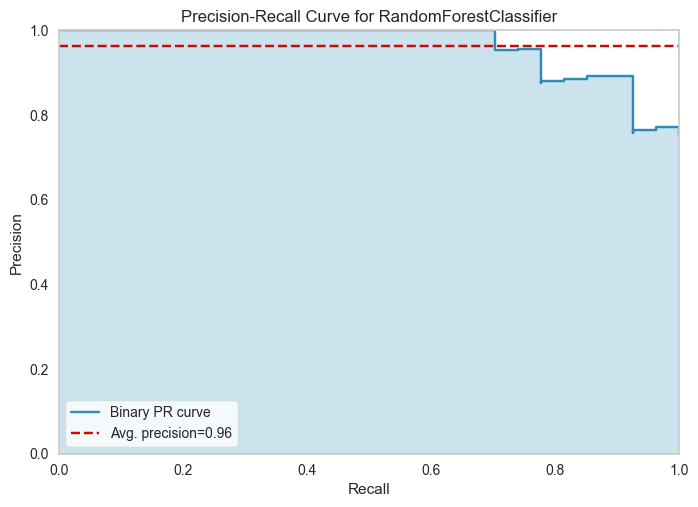

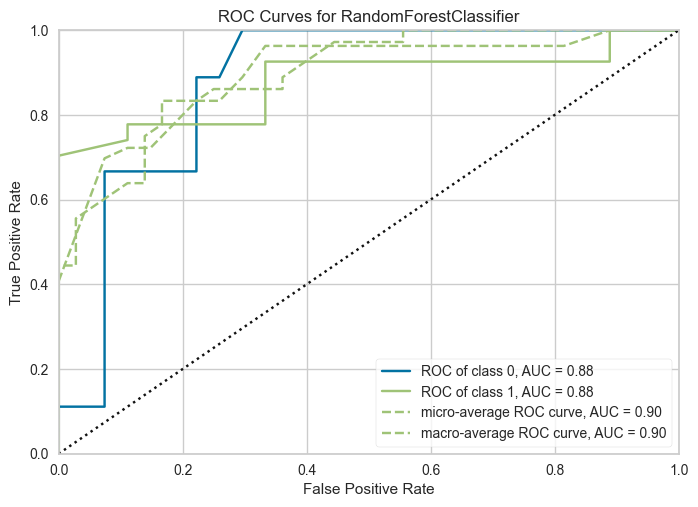

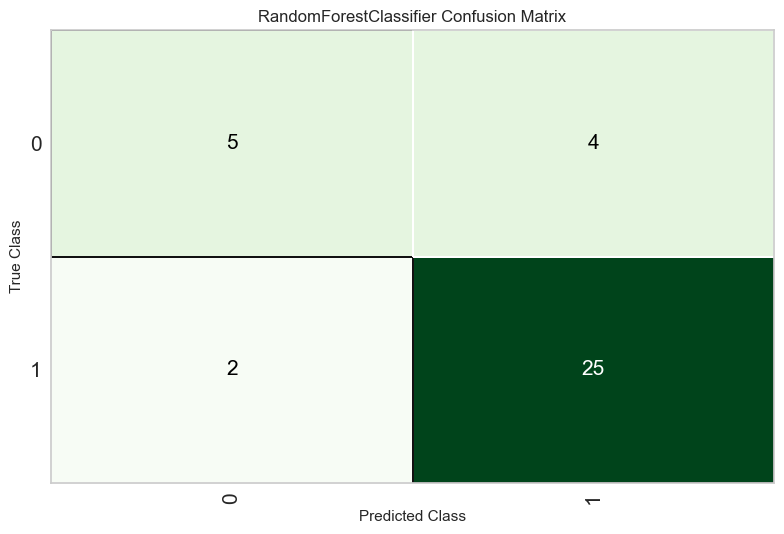

In [9]:
# Step 7: Performance metrics on cross-validation
plot_model(tuned_rf, plot='pr')
plot_model(tuned_rf, plot='auc')
plot_model(tuned_rf, plot='confusion_matrix')

### STEP 8: Sensitivity-fixed operating point thresholding
We fixed it at 90% senstivity as false positives are less consequential than false negatives

In [10]:
# Step 8: Sensitivity-fixed threshold from grouped OOF predictions
pipeline = get_config('pipeline')
full_pipeline = clone(pipeline)
full_pipeline.steps.append(('clf', clone(tuned_rf)))

ignore_cols = ['subject_id', 'samples', 'Species', 'Condition']
X_all = train_data.drop(columns=ignore_cols).reset_index(drop=True)
y_all = train_data['Condition'].reset_index(drop=True)
g_all = train_data['subject_id'].reset_index(drop=True)

# Alignment checks
assert len(X_all) == len(y_all) == len(g_all) == 178
assert X_all.index.equals(y_all.index) and y_all.index.equals(g_all.index)
assert g_all.notna().all()
assert list(X_all.columns) == list(get_config('X_train').columns), "Feature columns differ from setup()"

# Build folds once; the same folds are used for the checks and the predictions
folds = list(sgkf.split(X_all, y_all, groups=g_all))

# Leakage checks on the folds actually used
validation_count = np.zeros(len(X_all), dtype=int)
for k, (tr, va) in enumerate(folds, start=1):
    overlap = set(g_all.iloc[tr]) & set(g_all.iloc[va])
    assert not overlap, f"Subject leakage in fold {k}: {overlap}"
    validation_count[va] += 1
assert np.all(validation_count == 1), "Each sample must be validated exactly once"

paired = g_all[g_all.str.contains('paired')].unique()
assert len(paired) == 8, f"Expected 8 paired subjects in training, found {len(paired)}"
print("Pipeline steps:", [n for n, _ in full_pipeline.steps])

# OOF predictions: full pipeline (impute -> SMOTE -> normalize -> RF) refit inside each fold
oof_proba = cross_val_predict(full_pipeline, X_all, y_all, cv=folds, method='predict_proba')
oa_col = list(np.unique(y_all)).index('OA')
oof_scores = oof_proba[:, oa_col]

# Threshold: highest threshold with OOF sensitivity >= 0.90 (maximizes specificity under the floor)
fpr, tpr, thresholds = roc_curve(y_all, oof_scores, pos_label='OA', drop_intermediate=False)
valid = tpr >= 0.90
if not valid.any():
    raise ValueError("No threshold achieves 0.90 sensitivity")
idx = np.argmax(valid)
chosen_threshold = float(thresholds[idx])

# Verify directly against labels
pred = oof_scores >= chosen_threshold
is_oa = (y_all == 'OA').values
sens = pred[is_oa].mean()
spec = (~pred[~is_oa]).mean()
assert sens >= 0.90, f"Sensitivity floor violated: {sens}"
assert np.isclose(sens, tpr[idx]), "Threshold and labels disagree"

print("OOF AUC:", auc(fpr, tpr))
print("Threshold:", chosen_threshold)
print("OOF sensitivity:", sens)
print("OOF specificity:", spec)
print("Step 8 verified.")

Pipeline steps: ['label_encoding', 'numerical_imputer', 'categorical_imputer', 'balance', 'normalize', 'clean_column_names', 'clf']
OOF AUC: 0.9165480145546591
Threshold: 0.51
OOF sensitivity: 0.9069767441860465
OOF specificity: 0.6122448979591837
Step 8 verified.


### STEP 9: SHAP Analyses

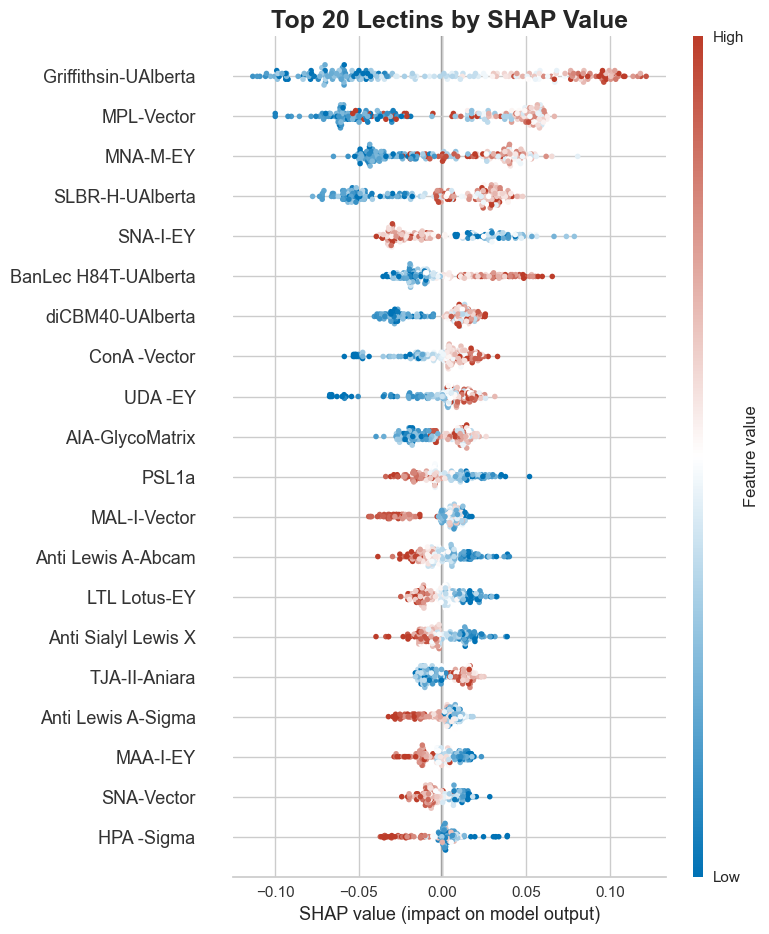

In [11]:
# Step 9a: SHAP of RF
# 1. Get the scaled data
X_train_transformed = get_config('X_train_transformed')

# 2. Extract the model
model_for_shap = tuned_rf.steps[-1][1] if hasattr(tuned_rf, 'steps') else tuned_rf

# 3. Initialize TreeExplainer
explainer = shap.TreeExplainer(model_for_shap)

# 4. Calculate SHAP values
shap_vals_raw = explainer.shap_values(X_train_transformed, check_additivity=False)

# 5. Extract just the OA class (index 1)
if isinstance(shap_vals_raw, list):
    shap_vals_oa = shap_vals_raw[1]
else:
    shap_vals_oa = shap_vals_raw[:, :, 1]

# 6. Custom Top-20 SHAP Plot Setup
colors = ['#0072B5', 'white', '#BC3C29']
cmap = LinearSegmentedColormap.from_list("nejm_cmap", colors)
mean_abs_vals = np.abs(shap_vals_oa).mean(axis=0)
top20_idx = np.argsort(mean_abs_vals)[-20:][::-1]
X_top20 = X_train_transformed.iloc[:, top20_idx]
shap_vals_top20 = shap_vals_oa[:, top20_idx]

# 7. Plot
plt.figure(figsize=(10, 8))
shap.summary_plot(shap_vals_top20, X_top20, plot_type="dot", cmap=cmap, show=False)
plt.title("Top 20 Lectins by SHAP Value", fontsize=18, fontweight='bold')
plt.tight_layout()
plt.savefig('shap_top20_fullmodel.svg', dpi=300, bbox_inches='tight')
plt.show()

### STEP 10: Finalize and predict model
Predict on external holdout set with threshold accounted for

In [12]:
# Step 10: Finalize and predict model
full_groups = pd.concat(
    [oa_train['subject_id'], oa_test['subject_id']], 
    ignore_index=True
)
final_rf = finalize_model(tuned_rf, groups=full_groups)

In [13]:

print("THRESHOLD PIPELINE")
for name, step in get_config("pipeline").steps:
    print(name, type(step).__name__)

print("\nFINAL MODEL")
print("Type:", type(final_rf).__name__)

if hasattr(final_rf, "steps"):
    for name, step in final_rf.steps:
        print(name, type(step).__name__)
else:
    print("No steps attribute. Inspect the finalized estimator:", final_rf)


THRESHOLD PIPELINE
label_encoding TransformerWrapperWithInverse
numerical_imputer TransformerWrapper
categorical_imputer TransformerWrapper
balance TransformerWrapper
normalize TransformerWrapper
clean_column_names TransformerWrapper

FINAL MODEL
Type: Pipeline
label_encoding TransformerWrapperWithInverse
numerical_imputer TransformerWrapper
categorical_imputer TransformerWrapper
balance TransformerWrapper
normalize TransformerWrapper
clean_column_names TransformerWrapper
actual_estimator RandomForestClassifier


In [14]:
# Step 10b: Predict Model with threshold strategy
rf_model = predict_model(final_rf, data=holdout_data, probability_threshold=chosen_threshold, raw_score = True)
print(rf_model[['Species', 'Condition', 'prediction_label','prediction_score_OA', 'prediction_score_Healthy']])

,Model,Accuracy,AUC,Recall,Prec.,F1,Kappa,MCC
0,Random Forest Classifier,0.8222,0.8168,0.8222,0.8351,0.8269,0.5466,0.5501


   Species Condition prediction_label  prediction_score_OA  \
0      Dog   Healthy          Healthy                 0.31   
1      Dog   Healthy          Healthy                 0.35   
2      Dog        OA               OA                 0.60   
3      Dog        OA               OA                 0.90   
4      Dog        OA               OA                 0.90   
5      Dog        OA               OA                 0.99   
6      Dog        OA               OA                 0.98   
7      Dog        OA               OA                 0.99   
8      Dog        OA               OA                 0.72   
9      Dog        OA               OA                 0.81   
10     Dog        OA               OA                 1.00   
11     Dog        OA               OA                 0.91   
12   Horse   Healthy          Healthy                 0.44   
13   Horse   Healthy          Healthy                 0.44   
14   Horse   Healthy          Healthy                 0.37   
15   Hor

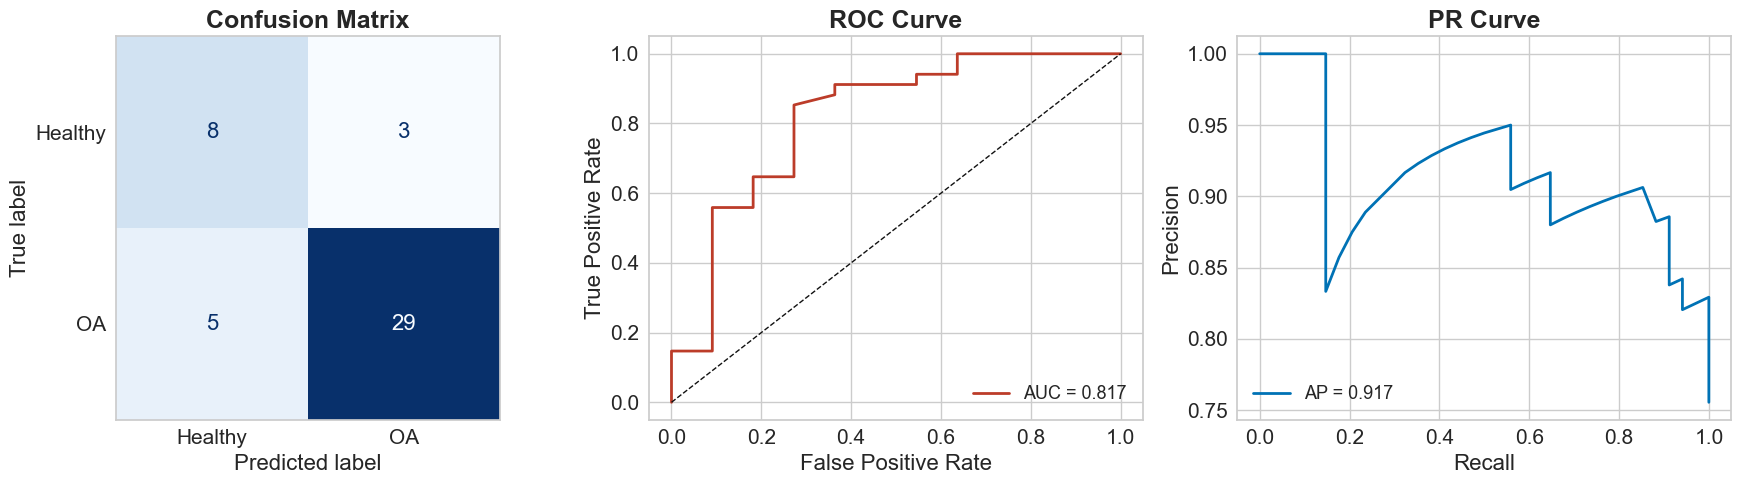

Independent Holdout Performance
Threshold: 0.51
  Selected on: out-of-fold (grouped CV) predictions on training data.
  Criterion: highest threshold meeting the 90% sensitivity floor on grouped out of fold predictions.
N = 45 (OA: 34, Healthy: 11)
ROC AUC:      0.817
Sensitivity:  0.853  (29/34 OA correct)
Specificity:  0.727  (8/11 Healthy correct)
Precision:    0.906
AP:           0.917

              precision    recall  f1-score   support

     Healthy       0.62      0.73      0.67        11
          OA       0.91      0.85      0.88        34

    accuracy                           0.82        45
   macro avg       0.76      0.79      0.77        45
weighted avg       0.84      0.82      0.83        45



In [15]:
# Step 10c: Independent holdout metrics and plots (sklearn)

y_true_ho = (rf_model['Condition'] == 'OA').astype(int)
y_prob_ho = rf_model['prediction_score_OA']
y_pred_ho = (rf_model['prediction_label'] == 'OA').astype(int)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

cm = confusion_matrix(y_true_ho, y_pred_ho, labels=[0, 1])
disp = ConfusionMatrixDisplay(cm, display_labels=['Healthy', 'OA'])
disp.plot(ax=axes[0], cmap='Blues', colorbar=False)

axes[0].grid(False)
axes[0].tick_params(labelsize=14)
for t in disp.text_.ravel(): t.set_fontsize(16)
axes[0].set_title(f'Confusion Matrix: Holdout\n(threshold={chosen_threshold:.2f})', fontsize=16)

# ROC
fpr_ho, tpr_ho, _ = roc_curve(y_true_ho, y_prob_ho)
roc_auc_ho = auc(fpr_ho, tpr_ho)
axes[1].plot(fpr_ho, tpr_ho, color='#BC3C29', lw=2, label=f'AUC = {roc_auc_ho:.3f}')
axes[1].plot([0, 1], [0, 1], 'k--', lw=1)
axes[1].set_xlabel('False Positive Rate', fontsize=16)
axes[1].set_ylabel('True Positive Rate', fontsize=16)
axes[1].set_title('ROC Curve', fontsize=18, fontweight='bold')
axes[1].tick_params(labelsize=15)
axes[1].legend(loc='lower right', fontsize=13)
axes[0].set_title('Confusion Matrix', fontsize=18, fontweight='bold')
axes[0].set_xlabel('Predicted label', fontsize=16)
axes[0].set_ylabel('True label', fontsize=16)
axes[0].tick_params(labelsize=15)

# PR
prec_ho, rec_ho, _ = precision_recall_curve(y_true_ho, y_prob_ho)
ap_ho = average_precision_score(y_true_ho, y_prob_ho)
axes[2].plot(rec_ho, prec_ho, color='#0072B5', lw=2, label=f'AP = {ap_ho:.3f}')
axes[2].set_xlabel('Recall', fontsize=16)
axes[2].set_ylabel('Precision', fontsize=16)
axes[2].set_title('PR Curve', fontsize=18, fontweight='bold')
axes[2].tick_params(labelsize=15)
axes[2].legend(loc='lower left', fontsize=13)

plt.tight_layout()
plt.savefig('holdout_metrics.svg', dpi=300, bbox_inches='tight')
plt.show()

# Summary
sensitivity_ho = recall_score(y_true_ho, y_pred_ho)
specificity_ho = recall_score(1 - y_true_ho, 1 - y_pred_ho)

print("=" * 65)
print("Independent Holdout Performance")
print("=" * 65)
print(f"Threshold: {chosen_threshold}")
print(f"  Selected on: out-of-fold (grouped CV) predictions on training data.")
print(f"  Criterion: highest threshold meeting the 90% sensitivity floor on grouped out of fold predictions.")
print(f"N = {len(rf_model)} (OA: {int(y_true_ho.sum())}, "
      f"Healthy: {int((1 - y_true_ho).sum())})")
print(f"ROC AUC:      {roc_auc_ho:.3f}")
print(f"Sensitivity:  {sensitivity_ho:.3f}  ({int(y_pred_ho[y_true_ho == 1].sum())}"
      f"/{int(y_true_ho.sum())} OA correct)")
print(f"Specificity:  {specificity_ho:.3f}  ({int((1 - y_pred_ho)[y_true_ho == 0].sum())}"
      f"/{int((1 - y_true_ho).sum())} Healthy correct)")
print(f"Precision:    {precision_score(y_true_ho, y_pred_ho, zero_division=0):.3f}")
print(f"AP:           {ap_ho:.3f}")
print("=" * 65)
print()
print(classification_report(y_true_ho, y_pred_ho, target_names=['Healthy', 'OA']))